# 02 – Exploratory Data Analysis: patterns, causes and coincidences

**Stage 4 of the project.**

**Rule 1: EDA looks at the training data only.** If we studied the test set too, our ideas and rules
would be shaped by data that is supposed to be unseen.

**Rule 2: association is not causation.** Ice cream sales and drownings rise together, but heat causes both.

**Our advantage: physics.** We add three engineered features:

| Feature | Formula | Meaning |
|---|---|---|
| `temp_diff_k` | process − air temperature | Small → heat is not carried away |
| `power_w` | torque × speed × 2π / 60 | How hard the machine works |
| `strain_nm_min` | tool wear × torque | Stress on a worn tool |

Written findings: `docs/04_eda_findings.md`. Production version of this code: `src/eda.py`.

In [1]:
import sys
sys.path.append("..")          # lets Python find the src folder
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.data import load_prepared, split_train_test, SENSORS, PHYSICS_FEATURES
from src import eda

%matplotlib inline
from src.plotting import set_style
set_style()

df = load_prepared()
train, test = split_train_test(df)
print("Training runs:", len(train), "| failures:", train["failure"].sum())
train[SENSORS + PHYSICS_FEATURES + ["failure"]].head()

Training runs: 8000 | failures: 271


,air_temp_k,process_temp_k,speed_rpm,torque_nm,tool_wear_min,temp_diff_k,power_w,strain_nm_min,failure
4058,302.0,310.9,1456,47.2,54,8.9,7196.676675,2548.8,0
1221,297.0,308.3,1399,46.4,132,11.3,6797.736296,6124.8,0
6895,301.0,311.6,1357,45.6,137,10.6,6479.974671,6247.2,0
9863,298.9,309.8,1411,56.3,84,10.9,8318.864043,4729.2,0
8711,297.1,308.5,1733,28.7,50,11.4,5208.456932,1435.0,0


## 1. How do failed runs differ from normal runs?

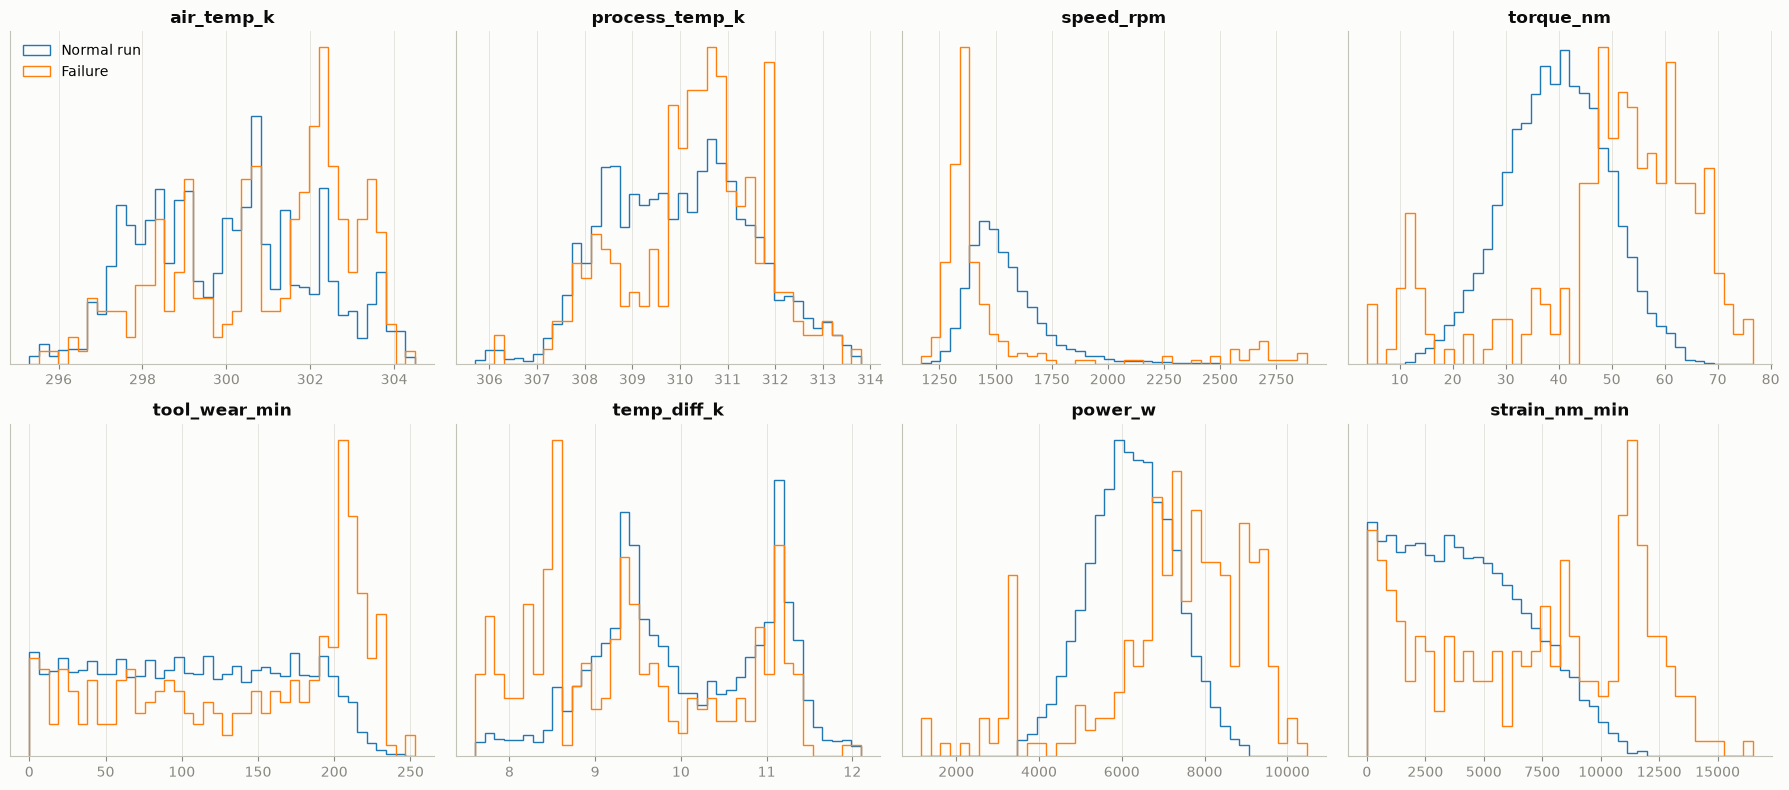

In [2]:
features = SENSORS + PHYSICS_FEATURES
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.flat, features):
    bins = np.histogram_bin_edges(train[col], bins=40)
    ax.hist(train.loc[train.failure == 0, col], bins=bins, density=True, histtype="step", label="Normal run")
    ax.hist(train.loc[train.failure == 1, col], bins=bins, density=True, histtype="step", label="Failure")
    ax.set_title(col)
    ax.set_yticks([])
axes.flat[0].legend()
plt.tight_layout()
plt.show()

In [3]:
train.groupby('failure')[features].median().T.round(1)

failure,0,1
air_temp_k,300.0,301.6
process_temp_k,310.0,310.5
speed_rpm,1507.0,1366.0
torque_nm,39.8,53.2
tool_wear_min,106.0,166.0
temp_diff_k,9.8,9.3
power_w,6244.4,7559.5
strain_nm_min,3948.0,7752.0


Failed runs have **higher torque, higher tool wear, higher strain and lower speed** than normal runs.

## 2. Correlation – and its blind spot

In [4]:
train[features].corrwith(train['failure']).sort_values().round(3)

temp_diff_k      -0.111
speed_rpm        -0.040
process_temp_k    0.041
air_temp_k        0.086
tool_wear_min     0.099
power_w           0.176
strain_nm_min     0.186
torque_nm         0.190
dtype: float64

All correlations with failure are **weak** (below 0.2). Does that mean the features are useless?
**No.** Correlation only measures *straight-line* relationships. Look at failure rate per power band:

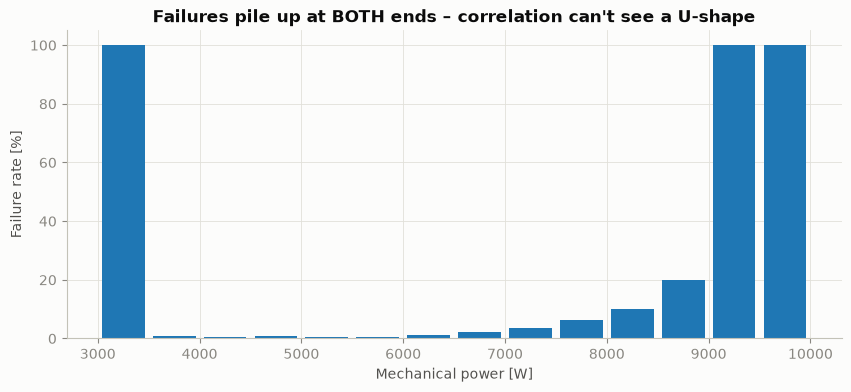

In [5]:
bands = pd.cut(train["power_w"], bins=np.arange(1000, 11001, 500))
rate = train.groupby(bands, observed=True)["failure"].agg(["mean", "size"])
rate = rate[rate["size"] >= 10]
plt.figure(figsize=(10, 4))
plt.bar([b.mid for b in rate.index], rate["mean"] * 100, width=420)
plt.xlabel("Mechanical power [W]")
plt.ylabel("Failure rate [%]")
plt.title("Failures pile up at BOTH ends – correlation can't see a U-shape")
plt.show()

**Lesson:** a weak correlation does *not* mean a weak relationship.
Power failures happen when power is too **low** *or* too **high**, so they cancel out in a correlation.
Always plot, never trust a single number.

Speed and torque are strongly negatively correlated (about −0.88): at roughly constant power,
higher speed means lower torque. That is physics, not a data error.

## 3. Failure mechanisms, one at a time

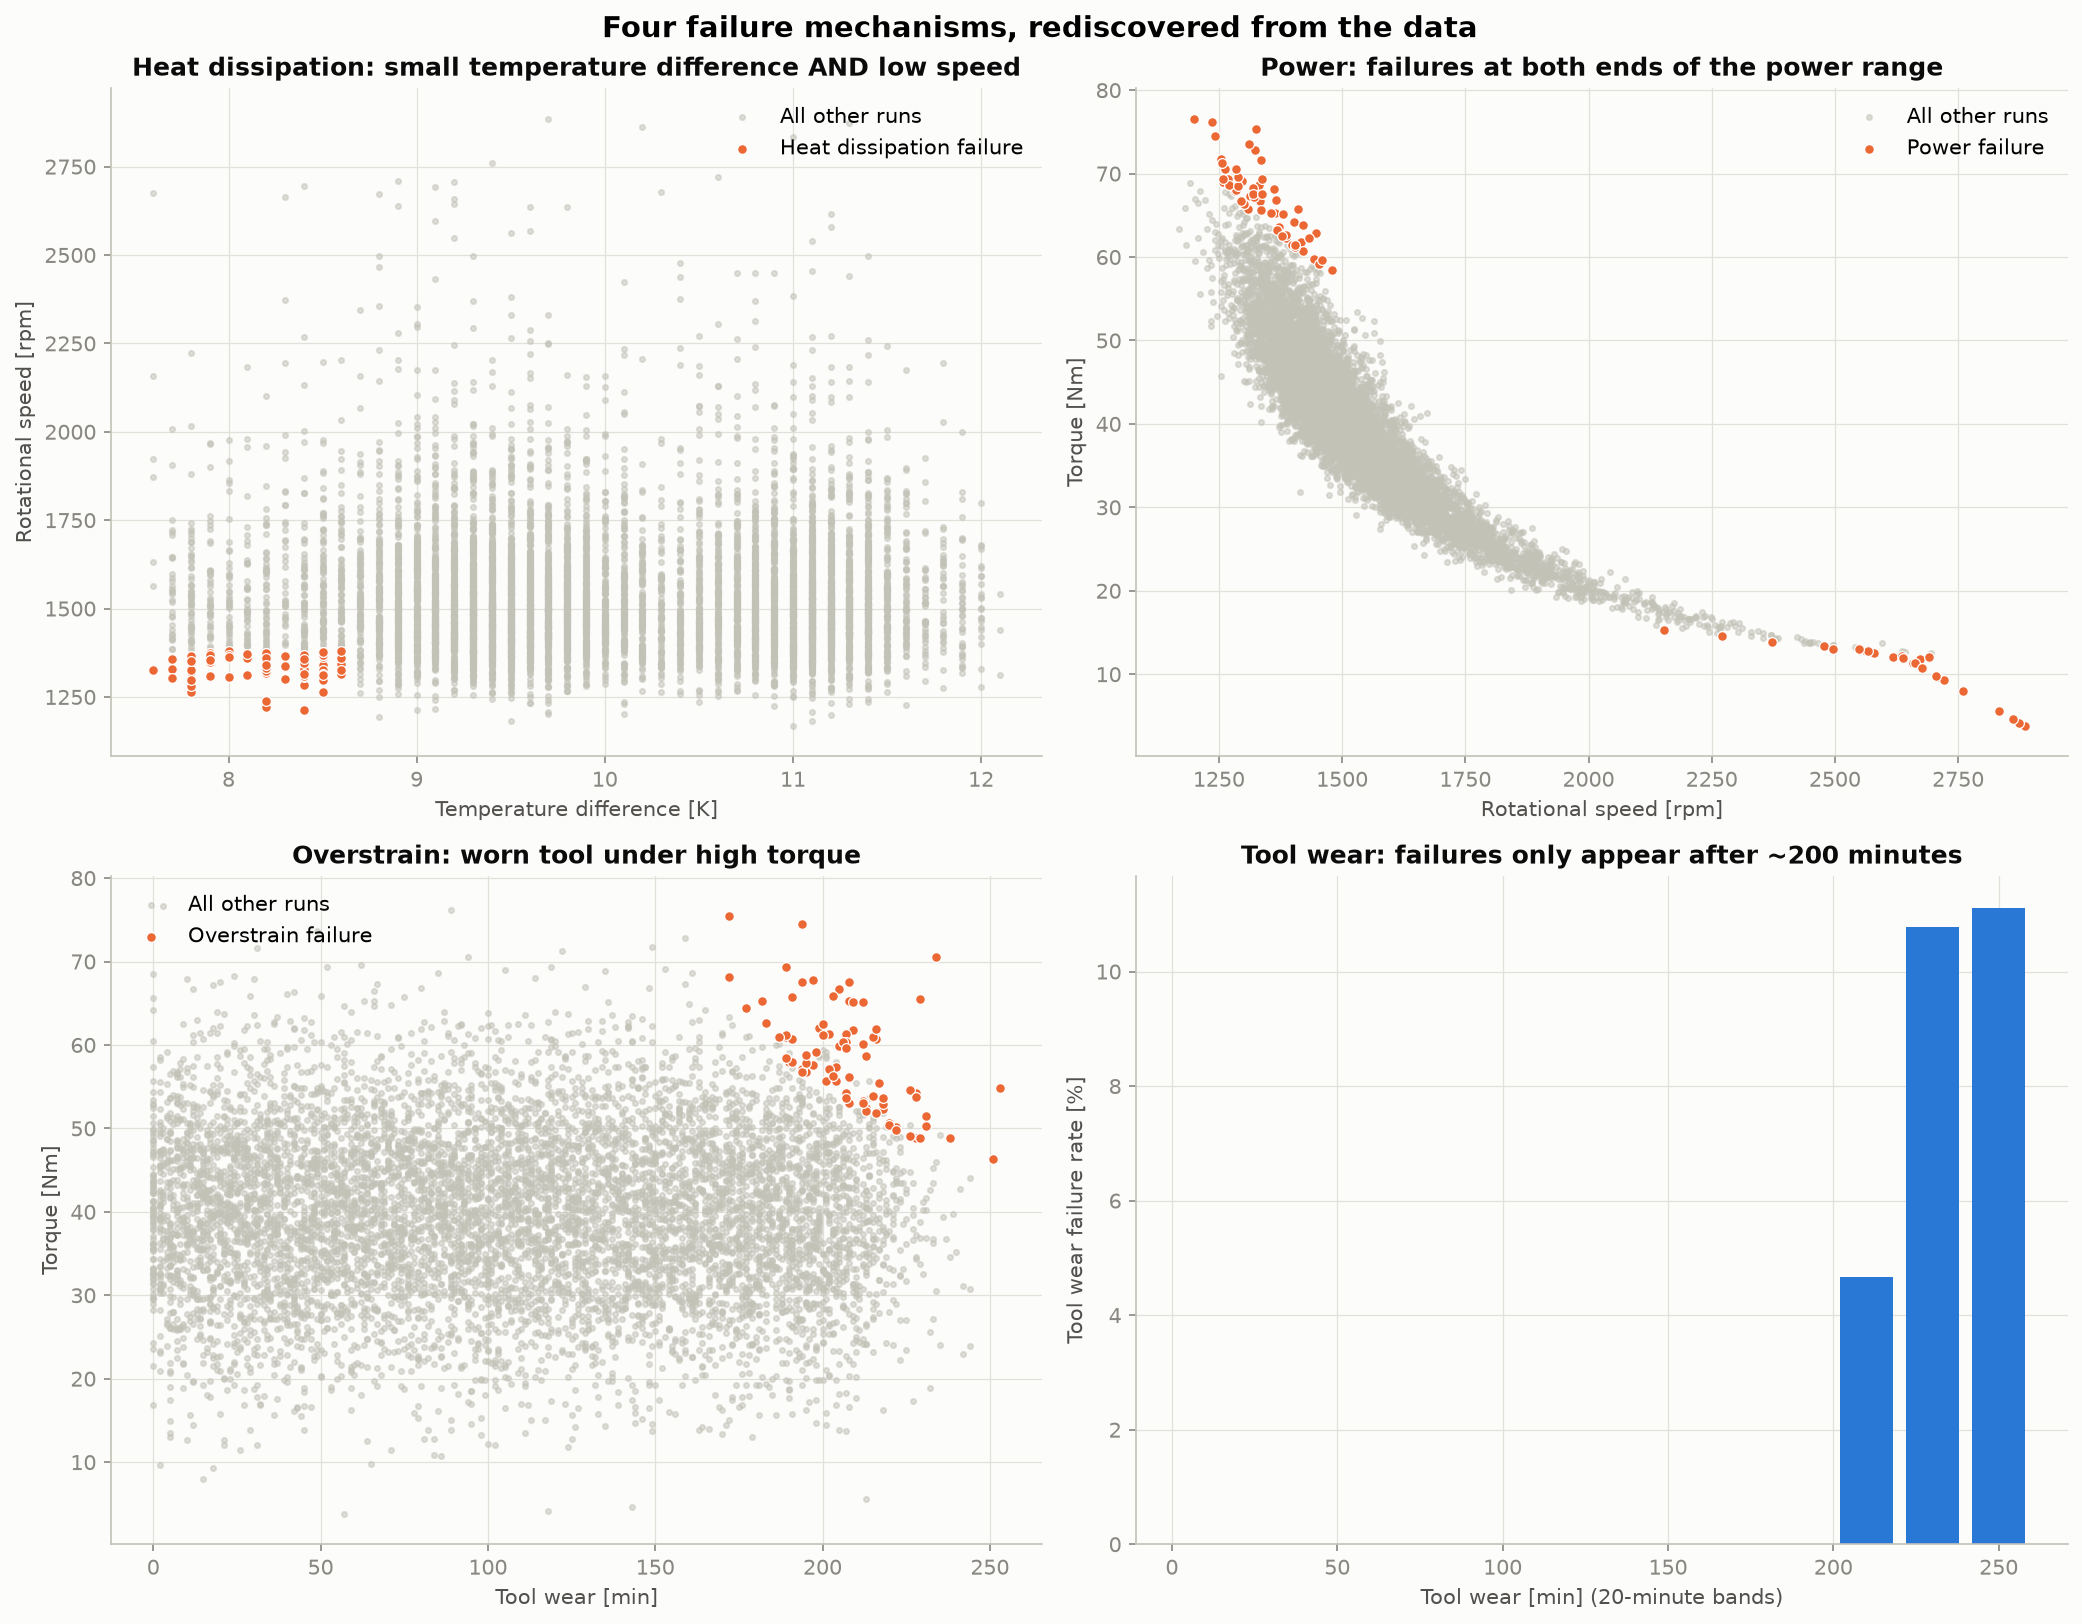

In [6]:
eda.plot_failure_mechanisms(train)
from IPython.display import Image
Image("../reports/figures/failure_mechanisms.png")

In [7]:
for t, cols in {"HDF": ["temp_diff_k", "speed_rpm"], "PWF": ["power_w"],
                "TWF": ["tool_wear_min"]}.items():
    print(t, train.loc[train[t] == 1, cols].agg(["min", "max"]).round(1).to_dict())
print("OSF minimum strain per variant:",
      train[train.OSF == 1].groupby("product_type")["strain_nm_min"].min().round(0).to_dict())

HDF {'temp_diff_k': {'min': 7.6, 'max': 8.6}, 'speed_rpm': {'min': 1212, 'max': 1379}}
PWF {'power_w': {'min': 1148.4, 'max': 10469.9}}
TWF {'tool_wear_min': {'min': 203, 'max': 253}}
OSF minimum strain per variant: {'H': 13582.0, 'L': 11003.0, 'M': 12337.0}


**What the data shows:**
- **Heat dissipation (HDF):** only when temperature difference ≤ 8.6 K **and** speed ≤ 1379 rpm
- **Power (PWF):** only when power is below ~3,500 W or above ~9,000 W
- **Overstrain (OSF):** only when strain exceeds a limit that **depends on the product variant**
  (≈11,000 for L, ≈12,300 for M, ≈13,600 for H)
- **Tool wear (TWF):** only after ~200 minutes, but **at a random moment** after that

Three mechanisms follow sharp physical limits. Tool wear does not – it will be the hardest to predict.

## 4. Why do L products fail more often? (association vs. causation)

In [8]:
rates = train.groupby("product_type")[["failure", "TWF", "HDF", "PWF", "OSF"]].mean().loc[["L", "M", "H"]] * 100
rates.round(2)

,failure,TWF,HDF,PWF,OSF
product_type,,,,,
L,4.08,0.43,1.33,1.08,1.53
M,2.44,0.38,0.71,1.05,0.29
H,2.03,0.76,0.63,0.63,0.13


L fails 2.05 percentage points more often than H. The biggest part of that gap is **overstrain**:
1.53% for L vs. 0.13% for H (1.40 points). Heat and power failures differ a little too, but their limits are
the same for every variant, and H has only about 800 training runs, so a handful of cases moves its rate a lot.

For overstrain we know the cause: the **strain limit is lower for L products**. So the variant does matter, but
*through one specific mechanism*. Saying "L products are bad" would be a lazy conclusion; saying
"L products tolerate less strain, so tool changes or torque limits should depend on the variant"
is an engineering conclusion a plant manager can act on.

## 5. What this means for modeling

1. The physics features should help models a lot → we compare *raw sensors* vs. *sensors + physics*.
2. Sharp limits → **tree-based models** (which learn thresholds) should beat linear models.
3. An **expert-rules baseline** built from these limits is a serious competitor the ML model must beat.
4. **Tool-wear failures** are random after ~200 min → expect most missed failures to be tool wear.